In [ ]:
from pyscf import gto, scf
import numpy as np
from oracles import *
import scipy as sp
from python_impls.pure_scf import *
from python_impls.cg_scf import *
from python_impls.cbcd_scf import *
from code_in_c.fast_scf import *   # ← add this line

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pgf import FigureCanvasPgf
from cycler import cycler
import awkward as ak
from pprint import pprint
from datetime import datetime
import json
from pathlib import Path
import re
from cycler import cycler
import json
import sys
import gc
# matplotlib 3.11's usetex PDF backend silently drops minus signs (log-axis
# exponents 10^{-n}, "$-$", etc.) — they show in PNG but not PDF. Route all
# .pdf saves through the pgf backend (typesets via pdflatex) so minuses embed
# correctly. PNG saves still use the default (Agg + usetex).
matplotlib.backend_bases.register_backend("pdf", FigureCanvasPgf)
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
    }
)
dp = 0.4
PRB_COLUMN_WIDTH = 246.0 / 72.27  # inches, PRB \columnwidth (3.404 in)
PRB_TEXT_WIDTH = 510.0 / 72.27  # inches, PRB \textwidth  (7.057 in)

OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7"]


plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "figure.titlesize": 10,
        "figure.figsize": (PRB_COLUMN_WIDTH, PRB_COLUMN_WIDTH * 0.75),
        "axes.prop_cycle": cycler(color=OKABE_ITO),
        "axes.unicode_minus": False,
        "pgf.texsystem": "pdflatex",
        "pgf.rcfonts": False,
        "figure.constrained_layout.use": True,
    }
)


basis = "6-31++g**"
distances = []
S66_DISTANCES = [0.9, 0.95, 1, 1.05, 1.1, 1.25, 1.5, 2.0]
s66 = True

based on e.g. James Shee's paper there are sort of 4 data sets to try and measure IMFs
* S22
* A24
* S66
* X31

however, one should also not be able to capture dispersion that well with Hartree-Fock in the first place, right? This is a correlated system. 

So, we should focus on polar systems, not nonpolar systems.

honestly, to me s66 is probably sufficient, especialyl since the data is already generated at various geometries

There is one for X40 but this is for halogenated molecules
S22x5 for noncovalent complexes





In [2]:
import re

DISPLAY_NAME = {"Water": r"H$_2$O", "MeOH": "MeOH", "Peptide": "peptide", "Pyridine": "pyridine"}

def display_name(mol):
    return DISPLAY_NAME.get(mol, chem_to_latex(mol))

def chem_to_latex(formula):
    return r"$\mathrm{" + re.sub(r"(\d+)", r"_{\1}", formula) + r"}$"

In [3]:
# TODO: sort out moving systems, i.e. what does it mean for one system to be 5 angstrom away from another?
# Systems: CH4/HCHO, check C-H----O bond
# H-bonding: 2 waters along the H---O-H axis?
# benchamrk on S66
# dimerization: BH3-BH3
# CH4-Ar
# HCHO-HCHO dimer
# check S66/A24 sets

In [ ]:
def get_ind_molecule_posns(composite_str):
    strs = composite_str.split("--")
    strs[1] = "units Angstrom" + strs[1]
    return [clean_fragment(s) for s in strs]

def clean_fragment(frag_str):
    lines = []
    for line in frag_str.strip().splitlines():
        line = line.strip()
        if not line:
            continue
        if line.lower().startswith("units"):
            continue
        if re.match(r'^-?\d+\s+\d+$', line):   # charge/multiplicity line, e.g. "0 1"
            continue
        if "--" in line:
            continue
        lines.append(line)
    return "\n".join(lines)

with open(
    "../psi4/dimers.json",
    "r",
) as file:
    json_dict = json.load(file)

with open(
    "../psi4/labels.json",
    "r",
) as file:
    labels = json.load(file)

data_dict = {}

cand_indices = {}


str_to_molecule = {
    "OHH": "Water",
    "OHCHHH": "MeOH",
    "NHHCHHH": "MeNH2",
    "CHHHCONHCHHH": "Peptide",
    "NHCOCHCHNHCO": "Uracil",
    "NCHCHCHCHCH": "Pyridine",
    "COOHCHHH": "AcOH",
    "CONHHCHHH": "AcNH2",
    "CHCHCHCHCHCH": "Benzene",
    "CHHCHH": "Ethene",
    "CHCH": "Ethyne",
    "CHHCHHCHHCHHCHHH": "Pentane",
    "CCHHHCHHHCHHHCHHH": "Neopentane",
    "CHHCHHCHHCHHCHH": "Cyclopentane",
}


for key, [ind, dist, _, _, out_str] in json_dict.items():
    strs = get_ind_molecule_posns(out_str)
    if (labels[str(ind)][0], labels[str(ind)][1]) in cand_indices: 
        if ind not in cand_indices[(labels[str(ind)][0], labels[str(ind)][1])]:
            cand_indices[(labels[str(ind)][0], labels[str(ind)][1])].append(ind)
    else:
       cand_indices[(labels[str(ind)][0], labels[str(ind)][1])] = [] 
    data_dict[(dist, labels[str(ind)][0], labels[str(ind)][1], ind)] = (
        strs[0],
        strs[1],
        clean_fragment(out_str),
    )




In [5]:
mol1 = "Water"
mol2 = "MeOH"
s66 = True

pot_inds = cand_indices.get((mol1, mol2), [])
oth_pot_inds = cand_indices.get((mol2, mol1), [])

if not pot_inds and not oth_pot_inds:
    print("This combination does not exist in S66", file=sys.stderr)
    sys.exit()

if len(pot_inds) + len(oth_pot_inds) == 1:
    idx = (pot_inds or oth_pot_inds)[0]
else:
    idx = -1
    print(f"Candidate indices: {pot_inds}, {oth_pot_inds}")
    while idx not in pot_inds and idx not in oth_pot_inds:
        idx = int(input("Which Index? "))

if idx in oth_pot_inds:   # data_dict keys follow S66's label order
    mol1, mol2 = mol2, mol1

print(f"index = {idx}")

Candidate indices: [2], [8]
index = 2


In [ ]:
def run_molecule(mol, expressive=False, profile=False):
    prof_cst = 15 if profile else 1
    ne = mol.nelectron
    integ = build_integrals(mol)
    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    mf_guess = scf.RHF(mol)
    mf_guess.max_cycle = 0
    mf_guess.kernel()

    S = mf_guess.get_ovlp()
    X = np.real(sp.linalg.fractional_matrix_power(S, 0.5))
    C0_orth = X @ mf_guess.mo_coeff[:, : ne // 2]

    del mf_guess
    gc.collect()

    if expressive:
        print("\n")
    # if expressive: print("Molecule: ", molecule)

    
    mf = scf.RHF(mol)
    e_pyscf = mf.kernel() - mol.get_enuc()
    if expressive:
        print(f"non-nuclear_E : {e_pyscf}")

    if expressive:
        print(f"SCF")
    C_init = np.copy(C0_orth)
    mat, etar, prof_scf = pure_scf(
        f,
        C_init,
        timing=False,
        eps=1e-6,
        ITER_MAX=10000,
        expressive=False,
        damp_param=dp,
        opt_profiling=True,
    )
    if abs(etar - e_pyscf) > 1e-4:
        print(f"ERROR: Non-variational energy: gap = {etar - e_pyscf}")

    if expressive:
        print(f"Outer Iteration Count: {len(prof_scf)}")
    if expressive:
        print("CG")

    cg_times = []
    e_cg_times = []

    for i in range(prof_cst):
        C_init = np.copy(C0_orth)
        mat, etar, (time_cg, e_time_cg), (prof_scf_cg, prof_opt_cg) = cg_scf(
            f,
            grad,
            C_init,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
            opt_profiling=True,
        )
        cg_times.append(time_cg)
        e_cg_times.append(time_cg - e_time_cg)
        if abs(etar - e_pyscf) > 1e-4:
            print(f"ERROR: Non-variational energy: gap = {etar - e_pyscf}")

    time_cg = np.median(cg_times)
    e_time_cg = np.median(e_cg_times)

    if expressive:
        print(f"Outer Iteration Count: {len(prof_scf_cg)}")
        print(
            f"Inner Iteration Count: {sum([len(prof_opt)-1 for prof_opt in prof_opt_cg])}"
        )
        print(f"CG Time: {time_cg} s ({e_time_cg} s excluding Fock builds)")

    if expressive:
        print("CBCD, c = N_o")
    c_value = mat.shape[1]

    cbcd_times = []
    e_cbcd_times = []

    for i in range(prof_cst):
        C_init = np.copy(C0_orth)
        mat, etar, (time_cbcd, e_time_cbcd), (prof_scf_cbcd, prof_opt_cbcd) = cbcd_scf(
            f,
            grad,
            C_init,
            c_value,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
            opt_profiling=True,
            fast_proj=True,
        )
        cbcd_times.append(time_cbcd)
        e_cbcd_times.append(time_cbcd - e_time_cbcd)
        if abs(etar - e_pyscf) > 1e-4:
            print(f"ERROR: Non-variational energy: gap = {etar - e_pyscf}")

    time_cbcd = np.median(cbcd_times)
    e_time_cbcd = np.median(e_cbcd_times)

    if expressive:
        print(f"Outer Iteration Count: {len(prof_scf_cbcd)}")
        print(
            f"Inner Iteration Count: {sum([len(prof_opt)-1 for prof_opt in prof_opt_cbcd])} (amortized: {sum([len(prof_opt)-1 for prof_opt in prof_opt_cbcd])/c_value})"
        )
        print(f"CBCD Time: {time_cbcd} s ({e_time_cbcd} s excluding Fock builds)")
        print("\n")
    return (
        len(prof_scf),
        (
            len(prof_scf_cg),
            sum([len(prof_opt) - 1 for prof_opt in prof_opt_cg]),
            time_cg,
            e_time_cg,
        ),
        (
            len(prof_scf_cbcd),
            sum([len(prof_opt) - 1 for prof_opt in prof_opt_cbcd]),
            time_cbcd,
            e_time_cbcd,
        ),
        mat.shape[0],  # n_b
        mat.shape[1], etar
    )


def print_output(molecule, info="", print_info=True):
    results = run_molecule(molecule, expressive=True)
    if print:
        print(f"{info}")
        print(f"CG: inner iters: {results[1][1]}, outer iters: {results[1][0]}")
        print(
            f"CBCD: inner iters {results[2][1]} (amortized: {results[2][1] / results[-2]}), outer iters: {results[2][0]}"
        )
    return (results[1][1], results[2][1]), (results[1][3], results[2][3]), (results[-1])


def molecule_to_mol(molecule, lookup=True):
    if lookup:
        with open(f"../ref_data/{molecule}.txt") as f:
            mol_atom_str = "".join(f.readlines()[1:])  # skip header row
    else:
        mol_atom_str = molecule

    mol = gto.Mole()
    # mol.output = 'out_h2o'
    mol.atom = mol_atom_str
    mol.basis = basis
    mol.build()
    return mol

In [7]:
if not (s66):
    molecule_one_info = run_molecule(molecule_to_mol(mol1), True)
    molecule_two_info = run_molecule(molecule_to_mol(mol2), True)  # C=O bond on z-axis
else:
    lookup = data_dict[(S66_DISTANCES[0], mol1, mol2, idx)]
    molecule_one_info = run_molecule(molecule_to_mol(lookup[0].strip(), False), True)
    molecule_two_info = run_molecule(molecule_to_mol(lookup[1].strip(), False), True)

baseline_super_cg = max(molecule_one_info[1][1], molecule_two_info[1][1])
baseline_super_cbcd = molecule_one_info[2][1] + molecule_two_info[2][1]
ne_tot = molecule_one_info[-2] + molecule_two_info[-2]
baseline_super_amortized_cbcd = baseline_super_cbcd / ne_tot

cg_time_a = molecule_one_info[1][3]
cg_time_b = molecule_two_info[1][3]

cbcd_time_a = molecule_one_info[2][3]
cbcd_time_b = molecule_two_info[2][3]

nie = molecule_one_info[-1] + molecule_two_info[-1]

print("\n")


print(
    f"CG: inner iters for {mol1}: {molecule_one_info[1][1]}, {mol2}: {molecule_two_info[1][1]}"
)
print(
    f"CBCD: inner iters for {mol1}: {molecule_one_info[2][1]} (amortized: {molecule_one_info[2][1] / molecule_one_info[-2]}), {mol2}: {molecule_two_info[2][1]}  (amortized: {molecule_two_info[2][1] / molecule_two_info[-2]})"
)

print(f"N_e = {molecule_one_info[-2]}")

print(f"Expected inner iters for supersystem CG: {baseline_super_cg}")
print(
    f"Expected inner iters for supersystem CBCD: {baseline_super_cbcd}  (amortized: {baseline_super_amortized_cbcd})")
print(f"N_e = {molecule_two_info[-2]}")

print(f"Noninteracting energy: {nie}")

SCF not converged.
SCF energy = -75.8473342022495


converged SCF energy = -76.0300459530139
non-nuclear_E : -85.18000865083602
SCF
Outer Iteration Count: 9
CG
Outer Iteration Count: 9
Inner Iteration Count: 72
CG Time: 0.0005103749863337725 s (0.00013095996109768748 s excluding Fock builds)
CBCD, c = N_o
Outer Iteration Count: 9
Inner Iteration Count: 210 (amortized: 42.0)
CBCD Time: 0.0004882079956587404 s (7.187700248323381e-05 s excluding Fock builds)


SCF not converged.
SCF energy = -115.059518864006


converged SCF energy = -115.05126019722
non-nuclear_E : -155.34588914657542
SCF
Outer Iteration Count: 10
CG
Outer Iteration Count: 10
Inner Iteration Count: 93
CG Time: 0.006285165989538655 s (0.0006946640205569565 s excluding Fock builds)
CBCD, c = N_o
Outer Iteration Count: 10
Inner Iteration Count: 442 (amortized: 49.111111111111114)
CBCD Time: 0.005653208994772285 s (0.0004047930415254086 s excluding Fock builds)




CG: inner iters for Water: 72, MeOH: 93
CBCD: inner iters fo

In [8]:
pref_cg_a = cg_time_a / (
    molecule_one_info[-1] * molecule_one_info[1][1] * (molecule_one_info[-2]) ** 2
)
pref_cg_b = cg_time_b / (
    molecule_two_info[-1] * molecule_two_info[1][1] * (molecule_two_info[-2]) ** 2
)

print("System A gives estimated prefactor for CG: ", pref_cg_a)
print("System B gives estimated prefactor for CG: ", pref_cg_b)


pref_cbcd_a = cbcd_time_a / (molecule_one_info[2][1] * (molecule_one_info[-2]) ** 2)
pref_cbcd_b = cbcd_time_b / (molecule_two_info[2][1] * (molecule_two_info[-2]) ** 2)

print("System A gives estimated prefactor for CBCD: ", pref_cbcd_a)
print("System B gives estimated prefactor for CBCD: ", pref_cbcd_b)

pref_cg = (pref_cg_a + pref_cg_b) / 2

pref_cbcd = (pref_cbcd_a + pref_cbcd_b) / 2

print("Estimated prefactor for CG: ", pref_cg)
print("Estimated prefactor for CBCD: ", pref_cbcd)

System A gives estimated prefactor for CG:  -8.541386125631798e-10
System B gives estimated prefactor for CG:  -5.93618017257691e-10
System A gives estimated prefactor for CBCD:  1.3690857615854059e-08
System B gives estimated prefactor for CBCD:  1.1306436554533507e-08
Estimated prefactor for CG:  -7.238783149104354e-10
Estimated prefactor for CBCD:  1.2498647085193783e-08


In [ ]:
def modify_molecule_z(molecule, offset):
    with open(f"../ref_data/{molecule}.txt") as f:
        mol_atom_str = "".join(f.readlines()[1:])  # skip header row

    strs = mol_atom_str.splitlines()
    out_str = ""

    for s in strs:
        coords = s.split("\t")
        coords[-1] = str(float(coords[-1]) + offset)
        for idx2, c in enumerate(coords):
            if idx2 == len(coords) - 1:
                out_str += c + "\n"
            else:
                out_str += c + "\t"

    return out_str


def franken_molecule(mol1, mol2, offset):
    with open(f"../ref_data/{mol1}.txt") as f:
        mol1_atom_str = "".join(f.readlines()[1:])  # skip header row

    mol2_atom_str = modify_molecule_z(mol2, offset)

    mol1_atom_str += "\n" + mol2_atom_str
    return mol1_atom_str

In [10]:
distances = S66_DISTANCES if s66 else np.logspace(0.3, 1.2, 10)

dist_cg = []
dist_cbcd = []


# print(data_dict[(distances[0], mol1, mol2)][0])

times_cg = []
times_cbcd = []
energies = []
for distance in distances:
    mol = gto.Mole()
    mol.atom = (
        data_dict[(distance, mol1, mol2, idx)][-1]
        if s66
        else franken_molecule(mol1, mol2, distance)
    )
    # print(data_dict[(distance, mol1, mol2, idx)][-1])
    mol.basis = basis
    mol.build()
    print("Distance: ", distance, "\r")
    (cg_iters, cbcd_iters), (cg_timing, cbcd_timing), etar = print_output(
        mol, f"{mol1}---{mol2}, distance: {distance}")
    print(f"Interaction Energy: {etar - nie}")
    dist_cg.append(cg_iters)
    dist_cbcd.append(cbcd_iters)  # amortized by number of electrons in the system
    times_cg.append(cg_timing)
    times_cbcd.append(cbcd_timing)
    energies.append(etar)

    gc.collect()


Distance:  0.9 
SCF not converged.
SCF energy = -190.986377156982


converged SCF energy = -191.088063941421
non-nuclear_E : -272.6184885305397
SCF
Outer Iteration Count: 10
CG
Outer Iteration Count: 10
Inner Iteration Count: 100
CG Time: 0.02418145799310878 s (0.0030921229626983404 s excluding Fock builds)
CBCD, c = N_o
Outer Iteration Count: 10
Inner Iteration Count: 706 (amortized: 50.42857142857143)
CBCD Time: 0.02224679201026447 s (0.000827081996249035 s excluding Fock builds)


Water---MeOH, distance: 0.9
CG: inner iters: 100, outer iters: 10
CBCD: inner iters 706 (amortized: 50.42857142857143), outer iters: 10
Interaction Energy: -32.092591023100255
Distance:  0.95 
SCF not converged.
SCF energy = -190.967044849606


converged SCF energy = -191.089170422993
non-nuclear_E : -271.6052972226954
SCF
Outer Iteration Count: 10
CG
Outer Iteration Count: 10
Inner Iteration Count: 100
CG Time: 0.022309791995212436 s (0.0014423330430872738 s excluding Fock builds)
CBCD, c = N_o
Outer Iter

In [11]:
import os

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
out_dir = f"data/pseudo_embedding/{mol1}_{mol2}/{timestamp}"
os.makedirs(out_dir, exist_ok=True)


def to_native(x):
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    return [to_native(v) for v in x] if isinstance(x, (list, tuple)) else x


info = {
    "distances": to_native(distances),
    "dist_cg": to_native(dist_cg),
    "dist_cbcd": to_native(dist_cbcd),
    "times_cg": to_native(times_cg),
    "times_cbcd": to_native(times_cbcd),
    "basis_set": basis,
}

with open(f"{out_dir}/data.json", "w", encoding="utf-8") as json_file:
    json.dump(info, json_file, indent=4)

print(f"Output directory: {out_dir}")

Output directory: data/pseudo_embedding/Water_MeOH/2026-10-23_09-45-35


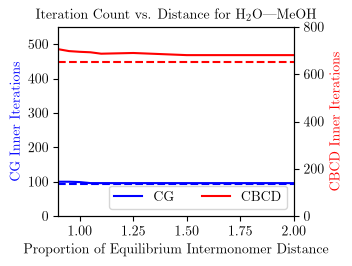

In [12]:
# 1. Create the figure and the first (left) axis

amortized = False

amor_factor = baseline_super_cbcd / baseline_super_amortized_cbcd if amortized else 1

fig, ax1 = plt.subplots()


ax1.plot(distances, dist_cg, color="blue", label="CG")
ax1.set_xlabel("Proportion of Equilibrium Intermonomer Distance")
ax1.set_ylabel("CG Inner Iterations", color="blue")
plt.axhline(y=baseline_super_cg, color="blue", linestyle="--")
ax1.set_ylim(0, 550)
ax2 = ax1.twinx()
ax2.plot(distances, np.array(dist_cbcd) / amor_factor, color="red", label="CBCD")
plt.axhline(y=baseline_super_cbcd / amor_factor, color="red", linestyle="--")
ax2.set_ylabel(
    "CBCD Inner Iterations" + (" (divided by N_o)" if amortized else ""), color="red"
)
ax2.set_ylim(0, 800)
ax2.set_xlim(distances[0], distances[-1])
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", ncols=2)


# 3. Display the plot
plt.title(
    f"Iteration Count vs. Distance for  {display_name(mol1)}---{display_name(mol2)}"
)
# plt.legend()
# plt.xscale("log")
plt.savefig(f"{out_dir}/iters_vs_distance.png", dpi=300)
plt.savefig(f"{out_dir}/iters_vs_distance.pdf")
plt.show()

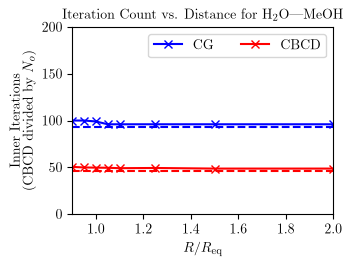

In [13]:
amortized = True
amor_factor = baseline_super_cbcd / baseline_super_amortized_cbcd if amortized else 1

fig, ax1 = plt.subplots()


ax1.plot(distances, dist_cg, color="blue", label="CG", marker = "x")
ax1.set_xlabel(r"$R/R_\mathrm{eq}$")
ax1.set_ylabel("Inner Iterations\n" + r"(CBCD divided by $N_o$)")
plt.axhline(y=baseline_super_cg, color="blue", linestyle="--")
ax1.set_ylim(0, 200)
# ax2 = ax1.twinx()
ax1.plot(distances, np.array(dist_cbcd) / amor_factor, color="red", label="CBCD", marker="x")
plt.axhline(y=baseline_super_cbcd / amor_factor, color="red", linestyle="--")
# ax2.set_ylabel(
#     r"CBCD Inner Iterations" + ("\n(divided by $N_o$)" if amortized else ""),
#     color="red",
# )
# ax2.set_ylim(0, 200)

# lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", ncols=2)
ax1.legend(loc="upper right", ncols=2)
ax1.set_xlim(distances[0], distances[-1])


# 3. Display the plot
plt.title(
    f"Iteration Count vs. Distance for  {display_name(mol1)}---{display_name(mol2)}"
)
# plt.xscale("log")

plt.savefig(f"{out_dir}/iters_vs_distance_amortized.png", dpi=300)
plt.savefig(f"{out_dir}/iters_vs_distance_amortized.pdf")
plt.show()

In [ ]:
from pathlib import Path

# Walk up from the notebook's cwd to the repo root (the dir containing manuscript/),
# so this works regardless of where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ref_data").is_dir())
# One subfolder per molecule pair, e.g. manuscript/new_figures/embedding_Water_MeOH/
FIGDIR = ROOT.parent / "manuscript" / "new_figures" / f"embedding_{mol1}_{mol2}"
FIGDIR.mkdir(parents=True, exist_ok=True)

fig.savefig(FIGDIR / "embedding_counts.pdf", bbox_inches="tight")
fig.savefig(FIGDIR / "embedding_counts.png", dpi=300, bbox_inches="tight")
print("wrote to", FIGDIR)

wrote to /Users/nilay/Library/CloudStorage/OneDrive-Personnel/Documents/Cornell/ManOpt/Code/Energies/manuscript/new_figures/embedding_Water_MeOH


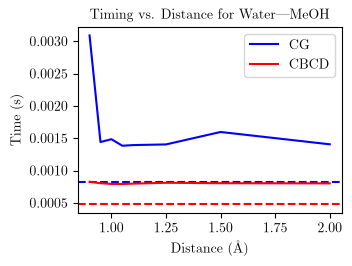

In [15]:
fig, ax = plt.subplots()

ax.plot(distances, times_cg, color="blue", label="CG")
plt.axhline(y=cg_time_a + cg_time_b, color="blue", linestyle="--")
ax.plot(distances, times_cbcd, color="red", label="CBCD")
ax.set_xlabel("Distance (Å)")
ax.set_ylabel("Time (s)")
plt.axhline(y=cbcd_time_a + cbcd_time_b, color="red", linestyle="--")
ax2.set_xlim(distances[0], distances[-1])

# 3. Display the plot
plt.title(f"Timing vs. Distance for  {chem_to_latex(mol1)}---{chem_to_latex(mol2)}")
plt.legend()
# plt.xscale("log")
plt.savefig(f"{out_dir}/timing_vs_distance.png", dpi=300)
plt.savefig(f"{out_dir}/timing_vs_distance.pdf")
plt.show()

In [16]:
print("Median speedup:", np.median(np.array(times_cg) / np.array(times_cbcd)))

Median speedup: 1.7725777279409365


In [17]:
#